# T24. Candidatos a estación

**Objetivo.** Crear un catálogo de emplazamientos a partir de las celdas H3 con demanda en el ajuste y revisar sobre el mapa los casos sensibles.

**Valor para el proyecto.** Los modelos de localización pueden compararse sobre un conjunto común con identificadores estables y un registro de las comprobaciones urbanas pendientes.

In [1]:
import gzip
import hashlib
import json

import h3
import numpy as np
import pandas as pd
import shapely
from IPython.display import display
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from pyproj import Transformer
from scipy.spatial.distance import cdist
from shapely.geometry import LineString, Polygon
from shapely.ops import linemerge, polygonize

from comun.config import cargar_config, carpeta_tablas, ruta
from comun.datos import cargar_viajes
from comun.figuras import guardar_figura, plt
from comun.geo import haversine_m
from comun.web import exportar

TEMA = "movilidad"
TABLAS = carpeta_tablas(TEMA)
cfg = cargar_config()
res = cfg["movilidad"]["resolucion_candidatos"]
solape_m = 2 * min(cfg["movilidad"]["radios_acceso_m"])
UMBRAL_ORILLA_M = 50
UMBRAL_VIA_M = 25
utm = Transformer.from_crs("EPSG:4326", "EPSG:32633", always_xy=True)
viajes = cargar_viajes(periodo="ajuste")

## 1. Una posición por celda con demanda

**Qué queremos ver.** Cuántas celdas tienen al menos un origen o un destino y cuántos extremos aporta cada una. Usamos la resolución de candidatos fijada en T13.

**Por qué importa.** Cada candidato tiene un peso trazable hasta los viajes de ajuste. La semana reservada queda para evaluar redes congeladas.

In [2]:
extremos = pd.concat([
    viajes[[f"lat{lado}", f"lon{lado}"]].set_axis(["lat", "lon"], axis=1).assign(lado=lado)
    for lado in ("O", "D")
], ignore_index=True)
extremos["candidate_id"] = [h3.latlng_to_cell(lat, lon, res) for lat, lon in zip(extremos["lat"], extremos["lon"])]
candidatos = (extremos.groupby(["candidate_id", "lado"]).size().unstack(fill_value=0)
              .reindex(columns=["O", "D"], fill_value=0)
              .rename(columns={"O": "origenes", "D": "destinos"}).sort_index())
candidatos.index.name = "candidate_id"
candidatos["extremos"] = candidatos["origenes"] + candidatos["destinos"]
assert candidatos["origenes"].sum() == candidatos["destinos"].sum() == len(viajes)

centros = np.array([h3.cell_to_latlng(cell) for cell in candidatos.index])
candidatos["lat_centro"], candidatos["lon_centro"] = centros.T
candidatos[["lat", "lon"]] = candidatos[["lat_centro", "lon_centro"]].to_numpy()
candidatos["cuota_extremos_pct"] = 100 * candidatos["extremos"] / len(extremos)

**Conclusiones.** La suma de orígenes y destinos del catálogo reconstruye todos los extremos del ajuste. El identificador H3 se mantiene aunque la posición propuesta dentro de la celda cambie tras la revisión.

## 2. Revisión de ríos, vías y proximidad

**Qué queremos ver.** Candidatos cuyo centro cae dentro del río, posiciones próximas a orillas o a vías con restricciones cartografiadas y separación entre emplazamientos vecinos. Se usa la instantánea de OpenStreetMap que guarda T36.

**Por qué importa.** Un centro de celda puede caer en el agua. Si hay un extremo observado en tierra dentro de esa misma celda, tomamos el más cercano al centro como alternativa. Los avisos a 50 m del río y 25 m de las vías sirven para priorizar revisión. Los vecinos con separación inferior a dos radios mínimos indican posible solape de cobertura. Todos los emplazamientos requieren comprobación urbana.

In [3]:
OSM = ruta("externos") / "osm"
meta = json.loads(sorted(OSM.glob("*.meta.json"))[-1].read_text(encoding="utf-8"))


def leer_capa(nombre):
    ficha = meta["capas"][nombre]
    datos = gzip.decompress((OSM / ficha["fichero"]).read_bytes())
    if hashlib.sha256(datos).hexdigest() != ficha["sha256"]:
        raise ValueError(f"La huella de la capa {nombre} no coincide con la archivada.")
    return json.loads(datos)["elements"]


def linea(geom):
    """Geometría de OpenStreetMap en metros UTM 33N."""
    if not geom or len(geom) < 2:
        return None
    x, y = utm.transform([p["lon"] for p in geom], [p["lat"] for p in geom])
    return LineString(zip(x, y))


agua = leer_capa("agua")
ejes_rio = []
piezas = []
for e in agua:
    trazo = linea(e.get("geometry"))
    if e.get("tags", {}).get("waterway") == "river" and trazo is not None:
        ejes_rio.append(trazo)
    if e.get("tags", {}).get("natural") != "water":
        continue
    if trazo is not None and trazo.is_ring:
        piezas.append(Polygon(trazo))
    elif e["type"] == "relation":
        anillos = {}
        for rol in ("outer", "inner"):
            trazos = [linea(m.get("geometry")) for m in e["members"] if m.get("role") == rol]
            segmentos = [trazo for trazo in trazos if trazo is not None]
            anillos[rol] = list(polygonize(linemerge(segmentos))) if segmentos else []
        if anillos["outer"]:
            piezas.append(shapely.union_all(anillos["outer"]).difference(shapely.union_all(anillos["inner"])))

superficie_rio = shapely.union_all([shapely.make_valid(p) for p in piezas])
assert superficie_rio.area > 0 and ejes_rio
rio = shapely.union_all([superficie_rio, *ejes_rio])

tramos_restringidos = []
for e in leer_capa("vias") + leer_capa("calles"):
    tags = e.get("tags", {})
    pie, acceso = tags.get("foot"), tags.get("access")
    restringida = (pie in {"no", "private"} or
                   (pie not in {"yes", "designated", "permissive"} and
                    (tags.get("highway") == "motorway" or
                     acceso in {"no", "private", "permit", "customers", "delivery", "residents"})))
    if restringida and (trazo := linea(e.get("geometry"))) is not None:
        tramos_restringidos.append(trazo)
vias_restringidas = shapely.union_all(tramos_restringidos)
assert not vias_restringidas.is_empty

caja = meta["caja"]
w, s, e, n = (caja[k] for k in ("oeste", "sur", "este", "norte"))
x_caja, y_caja = utm.transform([w, e, e, w], [s, s, n, n])
area_osm = Polygon(zip(x_caja, y_caja))
area_interior = area_osm.buffer(-max(UMBRAL_ORILLA_M, UMBRAL_VIA_M))

x, y = utm.transform(candidatos["lon"].to_numpy(), candidatos["lat"].to_numpy())
centros_utm = shapely.points(x, y)
centro_rio = shapely.covers(superficie_rio, centros_utm) & shapely.covers(area_osm, centros_utm)
candidatos["centro_en_rio"] = centro_rio

alternativas = extremos.loc[extremos["candidate_id"].isin(candidatos.index[centro_rio])].copy()
x_alt, y_alt = utm.transform(alternativas["lon"].to_numpy(), alternativas["lat"].to_numpy())
puntos_alt = shapely.points(x_alt, y_alt)
terreno = shapely.covers(area_osm, puntos_alt) & ~shapely.covers(superficie_rio, puntos_alt)
alternativas = alternativas.loc[terreno].join(candidatos[["lat_centro", "lon_centro"]], on="candidate_id")
alternativas["d_centro_m"] = haversine_m(alternativas["lat"], alternativas["lon"],
                                        alternativas["lat_centro"], alternativas["lon_centro"])
eleccion = (alternativas.sort_values(["d_centro_m", "lat", "lon"])
            .drop_duplicates("candidate_id").set_index("candidate_id"))
candidatos.loc[eleccion.index, ["lat", "lon"]] = eleccion[["lat", "lon"]]
candidatos["posicion"] = np.where(candidatos.index.isin(eleccion.index), "extremo_en_tierra", "centro_h3")

x, y = utm.transform(candidatos["lon"].to_numpy(), candidatos["lat"].to_numpy())
candidatos["x_m"], candidatos["y_m"] = x, y
puntos = shapely.points(x, y)
en_recorte = shapely.covers(area_interior, puntos)
d_rio = shapely.distance(puntos, rio)
d_via = shapely.distance(puntos, vias_restringidas)
candidatos["recorte_osm"] = en_recorte
candidatos["en_rio"] = shapely.covers(area_osm, puntos) & shapely.covers(superficie_rio, puntos)
candidatos["d_rio_m"] = np.where(en_recorte, d_rio, np.nan)
candidatos["d_via_restringida_m"] = np.where(en_recorte, d_via, np.nan)
candidatos["alerta_rio"] = en_recorte & (d_rio <= UMBRAL_ORILLA_M)
candidatos["alerta_via"] = en_recorte & (d_via <= UMBRAL_VIA_M)
candidatos["incluido_barrido"] = ~candidatos["en_rio"]
candidatos["estado_revision"] = "pendiente_revision_urbana"

distancias = cdist(np.column_stack([x, y]), np.column_stack([x, y]))
np.fill_diagonal(distancias, np.inf)
candidatos["d_vecino_m"] = distancias.min(axis=1)
candidatos["vecinos_en_solape"] = (distancias < solape_m).sum(axis=1)

x_ext, y_ext = utm.transform(extremos["lon"].to_numpy(), extremos["lat"].to_numpy())
referencias = candidatos.loc[extremos["candidate_id"], ["x_m", "y_m"]].to_numpy()
extremos["d_candidato_m"] = np.hypot(x_ext - referencias[:, 0], y_ext - referencias[:, 1])
candidatos["d_extremo_mas_proximo_m"] = extremos.groupby("candidate_id")["d_candidato_m"].min()
assert all(h3.latlng_to_cell(lat, lon, res) == cid
           for cid, lat, lon in candidatos[["lat", "lon"]].itertuples())

**Conclusiones.** Los avisos se leen por separado. Una vía restringida cerca del candidato puede convivir con acceso por otra calle. El recorte y las etiquetas archivadas limitan la detección y la instalación exige revisar el espacio público, la accesibilidad y los permisos.

## 3. Catálogo y mapa de revisión

**Qué queremos ver.** La demanda por candidato, las correcciones de posiciones y los casos que requieren una inspección prioritaria.

**Por qué importa.** La tabla permite seleccionar los mismos identificadores en T25–T28 y el mapa permite identificar qué revisar en la red final.

,resultado
resolucion,9.000
viajes_ajuste,16710.000
extremos_ajuste,33420.000
candidatos,600.000
centros_en_rio,7.000
desplazados,7.000
incluidos_barrido,600.000
proximos_rio,20.000
proximos_via,47.000
fuera_recorte,0.000


lado,candidate_id,extremos,posicion,en_rio,d_extremo_mas_proximo_m
39,891e805014fffff,145,extremo_en_tierra,False,0.0
50,891e8050183ffff,284,extremo_en_tierra,False,0.0
83,891e805033bffff,36,extremo_en_tierra,False,0.0
111,891e8050507ffff,143,extremo_en_tierra,False,0.0
373,891e805212bffff,78,extremo_en_tierra,False,0.0
536,891e8052c4fffff,2,extremo_en_tierra,False,0.0
564,891e8052e47ffff,19,extremo_en_tierra,False,0.0


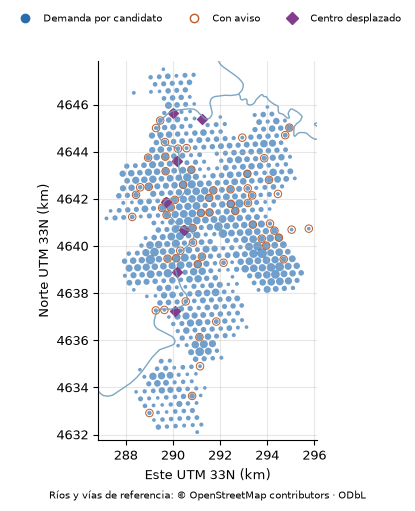

In [4]:
candidatos = candidatos.reset_index()
avisos = candidatos["alerta_rio"] | candidatos["alerta_via"] | ~candidatos["recorte_osm"] | candidatos["en_rio"]
resumen = pd.DataFrame([{
    "resolucion": res, "viajes_ajuste": len(viajes), "extremos_ajuste": len(extremos),
    "candidatos": len(candidatos), "centros_en_rio": int(centro_rio.sum()),
    "desplazados": len(eleccion), "incluidos_barrido": int(candidatos["incluido_barrido"].sum()),
    "proximos_rio": int(candidatos["alerta_rio"].sum()), "proximos_via": int(candidatos["alerta_via"].sum()),
    "fuera_recorte": int((~candidatos["recorte_osm"]).sum()), "candidatos_con_avisos": int(avisos.sum()),
    "d_vecino_min_m": candidatos["d_vecino_m"].min(), "solape_m": solape_m,
}]).round(3)
candidatos.to_csv(TABLAS / "T24_candidatos.csv", index=False, float_format="%.9f", lineterminator="\n")
resumen.to_csv(TABLAS / "T24_resumen.csv", index=False, lineterminator="\n")
display(resumen.T.rename(columns={0: "resultado"}))
display(candidatos.loc[candidatos["centro_en_rio"], ["candidate_id", "extremos", "posicion", "en_rio",
                                                     "d_extremo_mas_proximo_m"]].round(2))

rios_km = [np.asarray(trazo.simplify(10).coords) / 1_000 for trazo in ejes_rio]
x_km, y_km = x / 1_000, y / 1_000
fig, eje = plt.subplots(figsize=(6.7, 5.0), layout="constrained")
eje.add_collection(LineCollection(rios_km, colors="#709dbd", linewidths=1.0, alpha=0.9))
eje.scatter(x_km, y_km, s=5 + 2.0 * np.sqrt(candidatos["extremos"]), color="#286db0",
            linewidths=0, alpha=0.66)
eje.scatter(x_km[avisos], y_km[avisos], s=29, facecolors="none", edgecolors="#bc5c26", linewidths=0.7)
movidos = candidatos["posicion"].eq("extremo_en_tierra")
eje.scatter(x_km[movidos], y_km[movidos], s=25, marker="D", color="#823d8b")
eje.set(xlabel="Este UTM 33N (km)", ylabel="Norte UTM 33N (km)", aspect="equal",
        xlim=(x_km.min() - .35, x_km.max() + .35), ylim=(y_km.min() - .35, y_km.max() + .35))
eje.legend(handles=[
    Line2D([], [], linestyle="", marker="o", color="#286db0", label="Demanda por candidato"),
    Line2D([], [], linestyle="", marker="o", markerfacecolor="none", color="#bc5c26", label="Con aviso"),
    Line2D([], [], linestyle="", marker="D", color="#823d8b", label="Centro desplazado"),
], frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.15), ncol=3, fontsize=7.5)
fig.supxlabel("Ríos y vías de referencia: © OpenStreetMap contributors · ODbL", fontsize=7.5)
guardar_figura(fig, TEMA, "T24_mapa_candidatos")

datos_web = candidatos[["candidate_id", "x_m", "y_m", "origenes", "destinos", "extremos", "posicion", "centro_en_rio",
                        "alerta_rio", "alerta_via", "recorte_osm", "en_rio", "incluido_barrido", "d_vecino_m"]].copy()
datos_web["x_km"], datos_web["y_km"] = x_km.round(4), y_km.round(4)
exportar("fase1", "t24_candidatos", {
    "resumen": resumen.iloc[0].to_dict(), "candidatos": datos_web.drop(columns=["x_m", "y_m"]).round({"d_vecino_m": 2}),
    "rios": rios_km, "limites": [list(eje.get_xlim()), list(eje.get_ylim())],
})

**Conclusiones.** Los casos trasladados conservan su H3 y su demanda. La columna `incluido_barrido` identifica las posiciones que pasan a T25. Las columnas de proximidad permiten retomar la revisión al comparar las finalistas.